# Practical 1 · Linear regression, step by step (medical insurance charges)

**Goal:** predict a customer's yearly medical charges from age, sex, BMI, number of children, smoking and region.

We follow the **common recipe** from Part 3 of the handbook. Every heading has the same step number as the recipe, so you can look up the theory any time. Run each cell with **Shift + Enter**. Before running, read the text and guess what will happen.

## Step 0 · Set up the tools

In [1]:
import os
from urllib.request import urlretrieve
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings; warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8, 4.5)
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')
print('Tools ready')

Tools ready


## Step 1 · Load the data
We download the CSV file once, then read it into a **DataFrame** (a table) called `df`.

In [2]:
url = 'https://raw.githubusercontent.com/MusaBangash/Python-Variables/main/ml/data/medical-charges.csv'
if not os.path.exists('medical-charges.csv'):
    urlretrieve(url, 'medical-charges.csv')
df = pd.read_csv('medical-charges.csv')
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.90,0,yes,southwest,"16,884.92"
1,18,male,33.77,1,no,southeast,"1,725.55"
2,28,male,33.00,3,no,southeast,"4,449.46"
3,33,male,22.70,0,no,northwest,"21,984.47"
4,32,male,28.88,0,no,northwest,"3,866.86"


**What we see:** one row = one customer. Six columns describe the customer; `charges` is what we want to predict.

## Step 2 · First look

In [3]:
print('Rows and columns:', df.shape)
df.info()

Rows and columns: (1338, 7)
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB


**Reading `info()`:** 1,338 rows, no column has missing values (every *Non-Null Count* is 1,338). `age`, `bmi`, `children`, `charges` are numbers (`int64`/`float64`). `sex`, `smoker`, `region` are text (categories).

In [4]:
df.describe()

,age,bmi,children,charges
count,"1,338.00","1,338.00","1,338.00","1,338.00"
mean,39.21,30.66,1.09,"13,270.42"
std,14.05,6.10,1.21,"12,110.01"
min,18.00,15.96,0.00,"1,121.87"
25%,27.00,26.30,0.00,"4,740.29"
50%,39.00,30.40,1.00,"9,382.03"
75%,51.00,34.69,2.00,"16,639.91"
max,64.00,53.13,5.00,"63,770.43"


**Reading `describe()`:**
- age 18–64, BMI 16–53, children 0–5: all realistic.
- **charges:** the mean (~13,270) is much bigger than the median (50% row, ~9,380), and the max is ~63,770. A few customers are very expensive: the column is **skewed to the right**.

## Step 3 · Target, features and task type

In [5]:
target = 'charges'
features = ['age', 'sex', 'bmi', 'children', 'smoker', 'region']
print('Target:', target, '-> a number, so this is REGRESSION')
print('Features:', features)

Target: charges -> a number, so this is REGRESSION
Features: ['age', 'sex', 'bmi', 'children', 'smoker', 'region']


There is no ID column here, so nothing to drop.

## Step 4 · Check data quality

In [6]:
print('Missing values per column:')
print(df.isna().sum())
print()
print('Duplicate rows:', df.duplicated().sum())
df[df.duplicated(keep=False)]

Missing values per column:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Duplicate rows: 1


,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,"1,639.56"
581,19,male,30.59,0,no,northwest,"1,639.56"


No missing values, but **one customer appears twice**: identical in every column. If one copy lands in training and the other in testing, the model is tested on someone it has already seen (a small **leak**). We remove the duplicate.

In [7]:
df = df.drop_duplicates().reset_index(drop=True)
print('Rows after removing the duplicate:', len(df))
for col in ['sex', 'smoker', 'region']:
    print(col, '->', sorted(df[col].unique().tolist()))

Rows after removing the duplicate: 1337
sex -> ['female', 'male']
smoker -> ['no', 'yes']
region -> ['northeast', 'northwest', 'southeast', 'southwest']


The categories are clean (no spelling variants like 'Male' and 'male').

## Step 6 · Split into training and test sets

We split **before** exploring in detail, so the test rows stay truly unseen. (Step 5 comes after, on the training data only.)

In [8]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)
print('Training rows:', len(train_df))
print('Test rows (locked away until Step 19):', len(test_df))

Training rows: 1069
Test rows (locked away until Step 19): 268


## Step 5 · Explore and visualise (training data only)
### 5a · The target

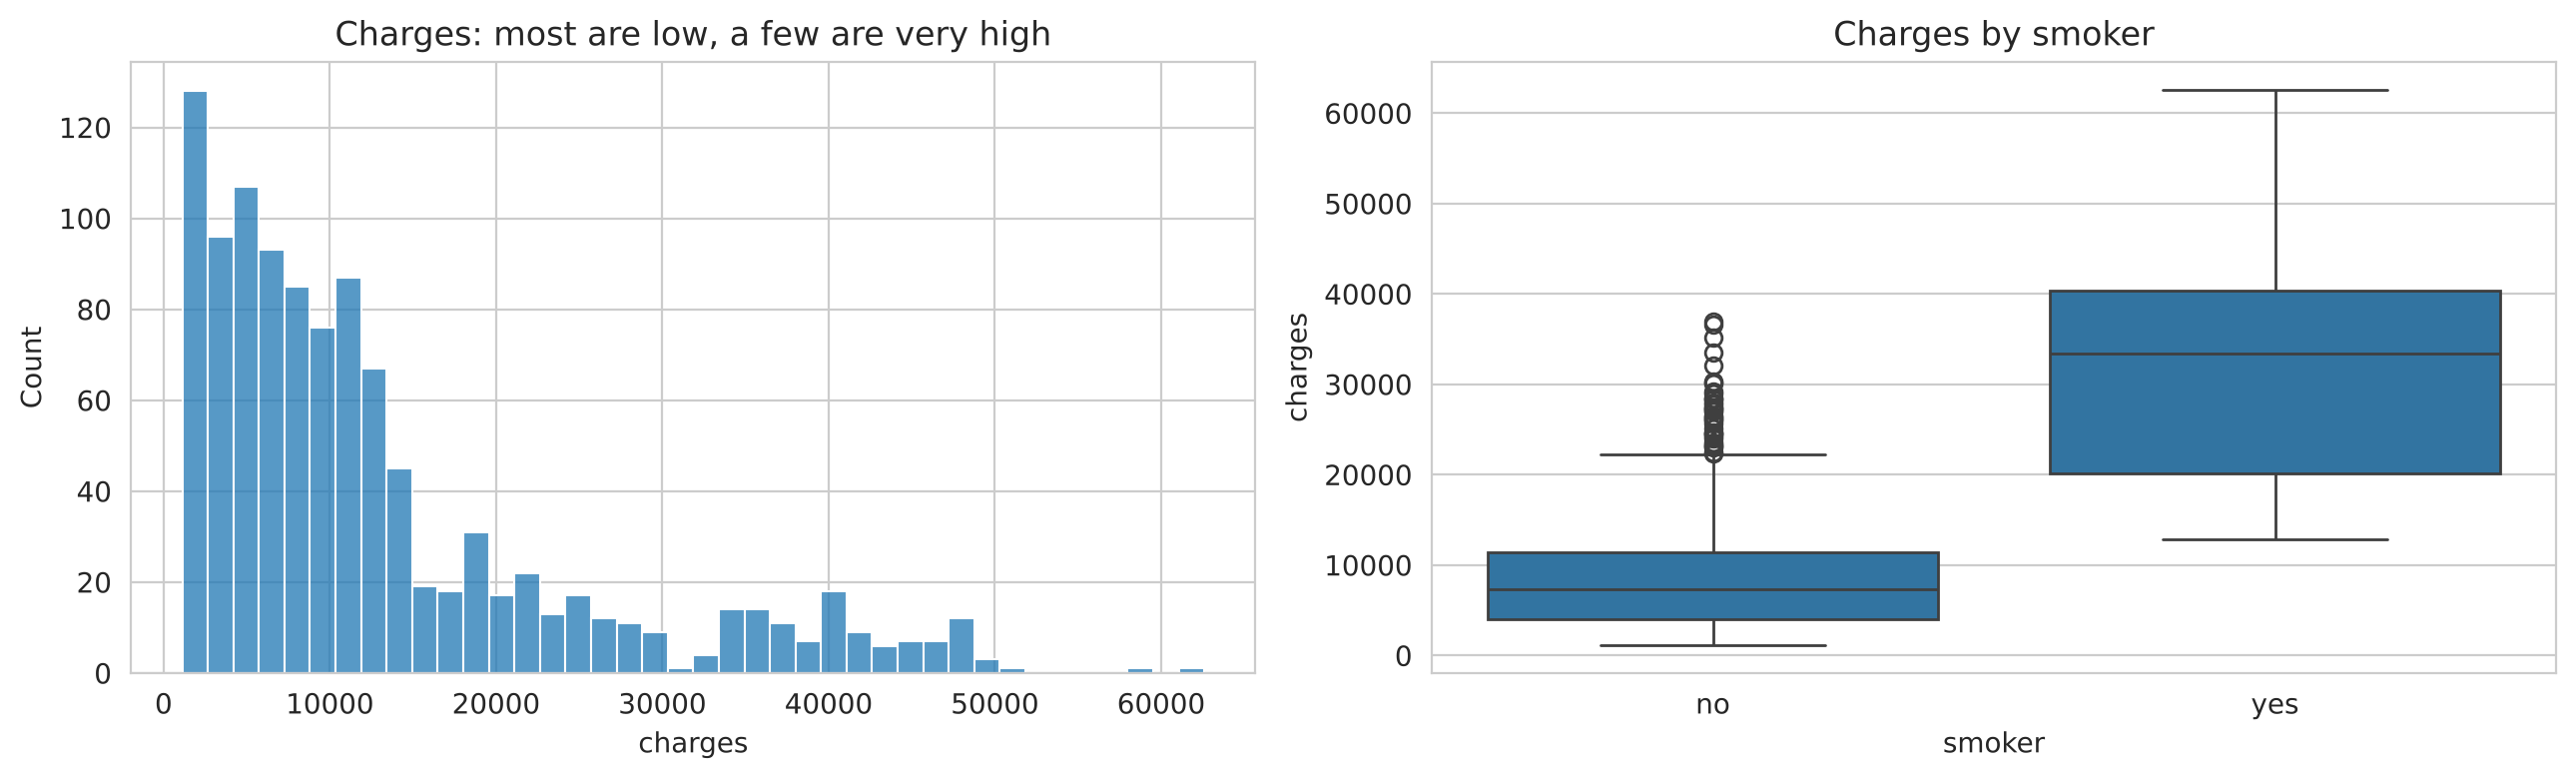

,median,mean,count
smoker,,,
no,"7,348.14","8,498.48",855
yes,"33,391.68","31,135.93",214


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(train_df['charges'], bins=40, ax=ax[0]); ax[0].set_title('Charges: most are low, a few are very high')
sns.boxplot(data=train_df, x='smoker', y='charges', ax=ax[1]); ax[1].set_title('Charges by smoker')
plt.tight_layout(); plt.show()
train_df.groupby('smoker')['charges'].agg(['median', 'mean', 'count'])

**Finding 1:** smokers pay far more: the median smoker costs about **4.5 times** a non-smoker. Smoking will be the most important feature.

### 5b · Age and charges

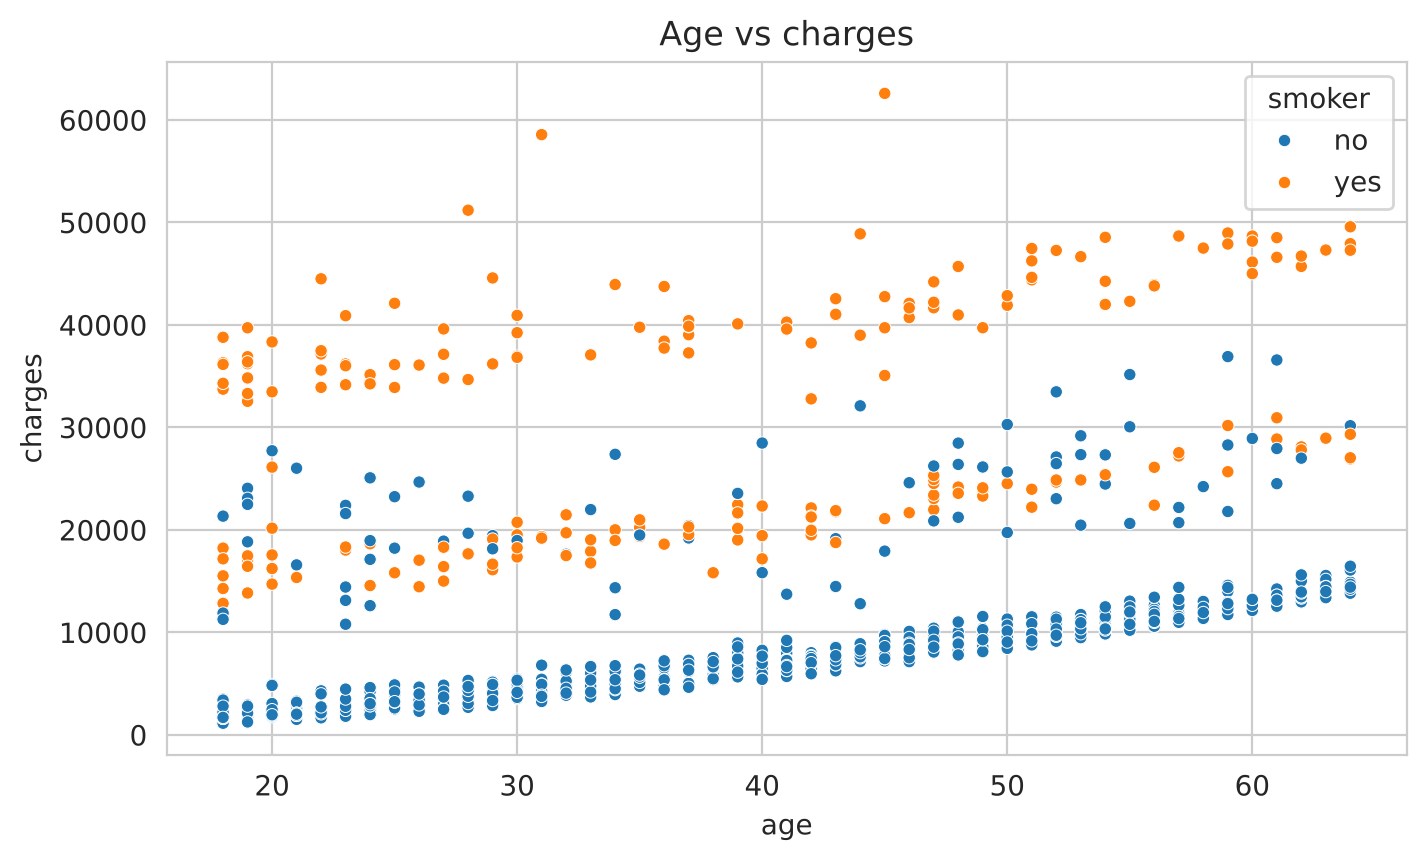

In [10]:
sns.scatterplot(data=train_df, x='age', y='charges', hue='smoker', s=20)
plt.title('Age vs charges'); plt.show()

**Finding 2:** charges rise steadily with age, in three bands. The top band is only smokers.

### 5c · BMI and charges

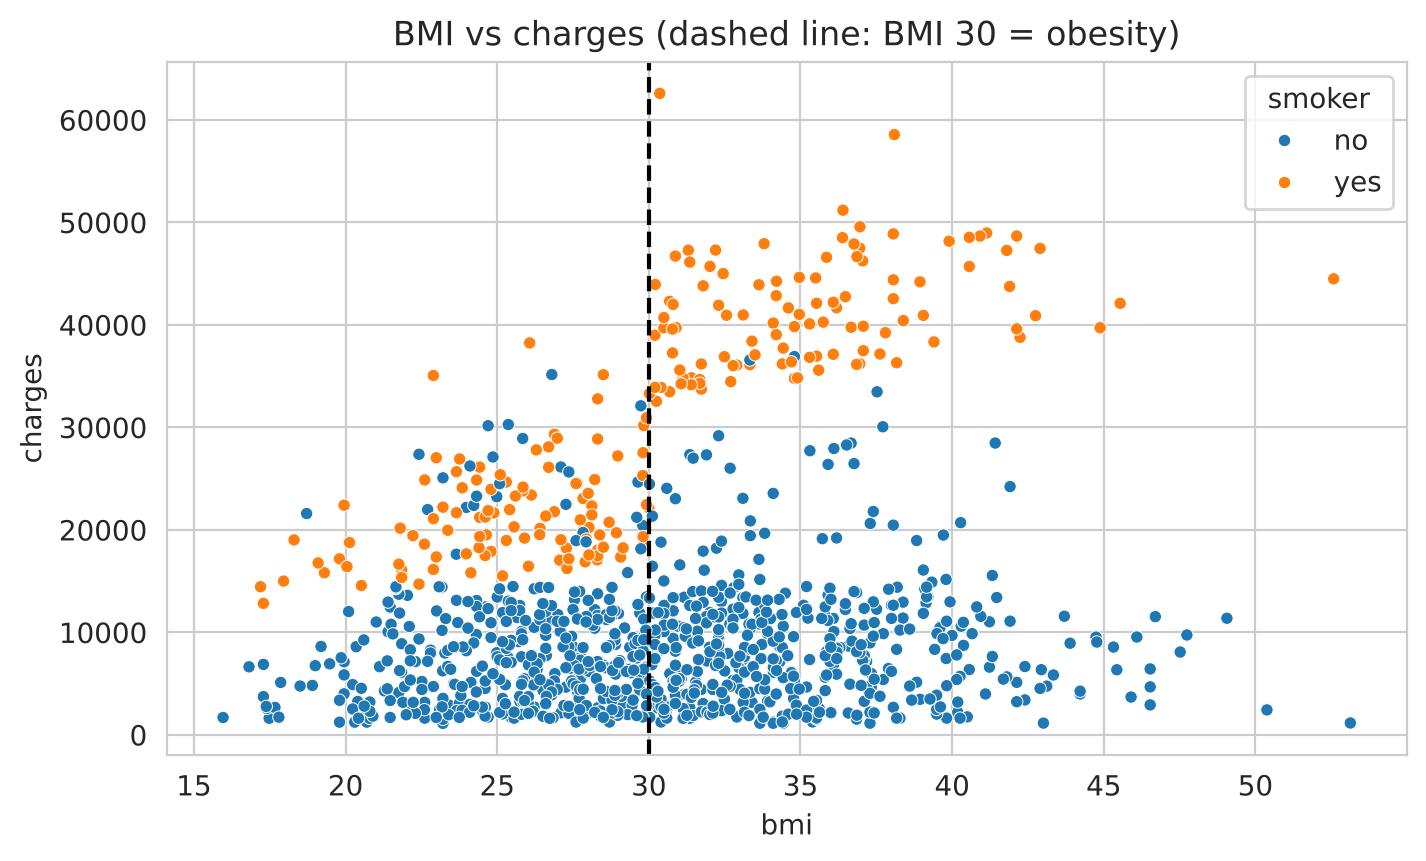

In [11]:
sns.scatterplot(data=train_df, x='bmi', y='charges', hue='smoker', s=20)
plt.axvline(30, color='black', linestyle='--'); plt.title('BMI vs charges (dashed line: BMI 30 = obesity)'); plt.show()

**Finding 3 (important):** for **non-smokers**, BMI hardly matters. For **smokers**, charges jump when BMI is 30 or more. The effect of BMI **depends on** smoking: this is called an **interaction**. A plain linear model cannot see it by itself. Remember this for Step 11.

### 5d · Correlation

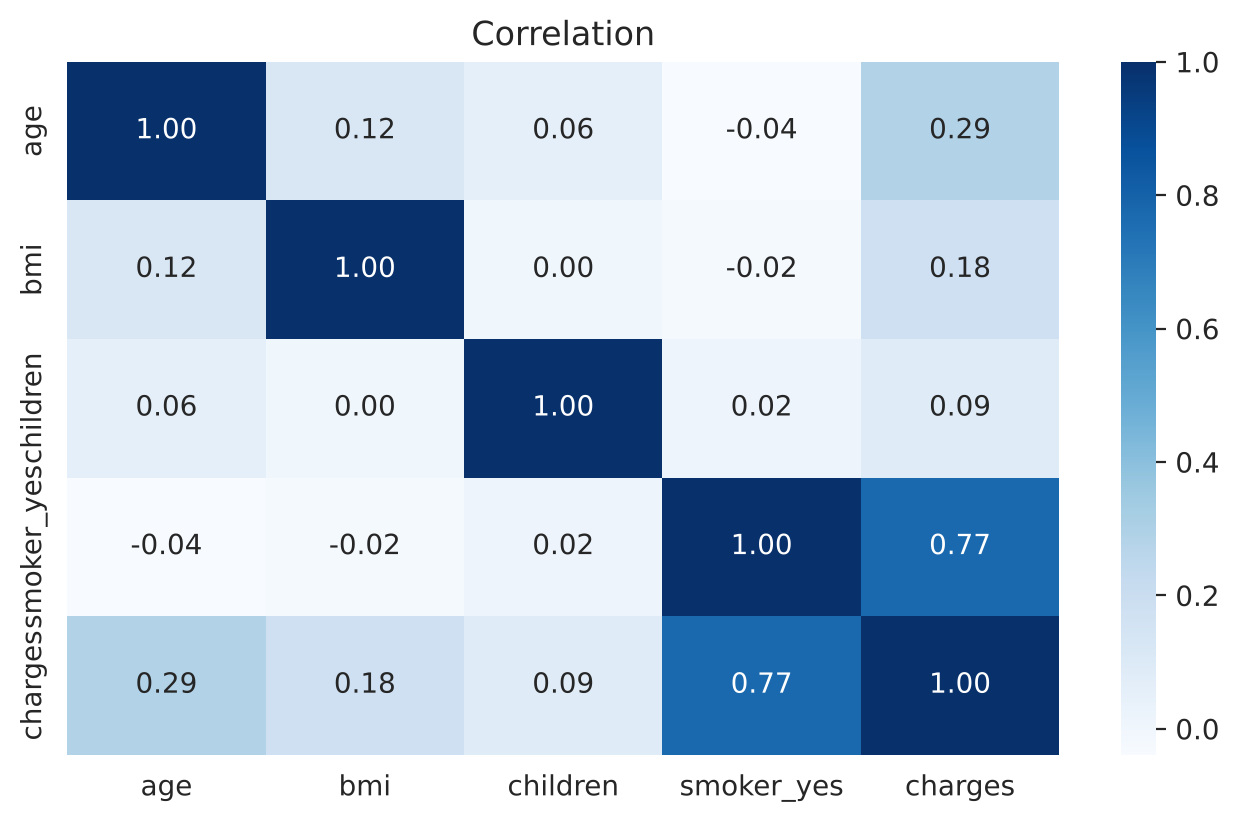

In [12]:
corr = train_df.assign(smoker_yes=(train_df['smoker'] == 'yes').astype(int))[['age', 'bmi', 'children', 'smoker_yes', 'charges']].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='Blues'); plt.title('Correlation'); plt.show()

**Finding 4:** with charges, smoker 0.77 (strong), age 0.29, BMI 0.18, children 0.09. Remember: BMI looks weak overall, but it is strong for smokers. Correlation only measures straight-line relationships across everyone.

## Step 7 · Feature types

In [13]:
X_train = train_df[features]
y_train = train_df[target]
X_test = test_df[features]
y_test = test_df[target]

numeric_cols = ['age', 'bmi', 'children']
categorical_cols = ['sex', 'smoker', 'region']
print('Numeric:', numeric_cols)
print('Categorical (no order -> one-hot):', categorical_cols)

Numeric: ['age', 'bmi', 'children']
Categorical (no order -> one-hot): ['sex', 'smoker', 'region']


## Step 8 · Missing values
We found none in Step 4. We still put an imputer in the pipeline, so that a future customer with a missing value doesn't crash the model.

## Step 9 · Encode categories (see one-hot encoding with your own eyes)

In [14]:
from sklearn.preprocessing import OneHotEncoder
enc = OneHotEncoder(drop='first', handle_unknown='ignore')
enc.fit(X_train[['region']])
example = X_train[['region']].head(5)
pd.concat([example.reset_index(drop=True),
           pd.DataFrame(enc.transform(example).toarray().astype(int), columns=enc.get_feature_names_out())], axis=1)

,region,region_northwest,region_southeast,region_southwest
0,northeast,0,0,0
1,northeast,0,0,0
2,northwest,1,0,0
3,southeast,0,1,0
4,northeast,0,0,0


Each region becomes 0/1 columns. `drop='first'` removes the first column (northeast): a row with all zeros means *northeast*. We drop one column because for linear regression the full set is redundant (the **dummy-variable trap**), which would make the weights hard to read.

## Step 10 · Scale numbers (see what scaling does)

In [15]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler().fit(X_train[numeric_cols])
print('Means learned from TRAINING rows:', sc.mean_.round(2))
pd.DataFrame(sc.transform(X_train[numeric_cols].head(5)), columns=numeric_cols).round(2)

Means learned from TRAINING rows: [39.2  30.54  1.08]


,age,bmi,children
0,-1.16,-1.00,-0.91
1,-1.30,-0.79,0.77
2,0.91,1.15,0.77
3,1.70,1.81,-0.91
4,0.56,-0.65,0.77


After scaling, each number says *how many standard deviations above or below average*. Age 0 = average age, +1 = one standard deviation older. Now the weights of different features become comparable.

## Step 12 · Build the pipeline
We put everything (imputing, encoding, scaling and the model) into one object. Fitting it learns everything from training rows only.

In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression

preprocess = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), numeric_cols),
    ('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                      ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore'))]), categorical_cols),
])
linear = Pipeline([('preprocess', preprocess), ('model', LinearRegression())])
linear

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the o

## Step 13 · Baseline
The simplest possible model predicts the **average** charge for everyone. Every real model must beat it. We measure with three metrics:
- **MAE:** average size of a miss, in dollars
- **RMSE:** like MAE, but big misses count more
- **R²:** share of the variation explained (0 = no better than the average, 1 = perfect)

We use **5-fold cross-validation** (Step 17) on the training data, so the test set stays locked.

In [17]:
from sklearn.model_selection import KFold, cross_validate
from sklearn.dummy import DummyRegressor

folds = KFold(n_splits=5, shuffle=True, random_state=42)
results = {}

def evaluate(name, model, X=X_train):
    cv = cross_validate(model, X, y_train, cv=folds,
                        scoring=('neg_mean_absolute_error', 'neg_root_mean_squared_error', 'r2'))
    results[name] = {'MAE': -cv['test_neg_mean_absolute_error'].mean(),
                     'RMSE': -cv['test_neg_root_mean_squared_error'].mean(),
                     'R2': cv['test_r2'].mean()}
    return pd.DataFrame(results).T

evaluate('Baseline (predict the mean)', DummyRegressor(strategy='mean'))

,MAE,RMSE,R2
Baseline (predict the mean),"8,789.32","11,688.80",-0.00


The baseline misses by about **\$9,000** on average and R² is 0 (by definition).

## Step 15 · Train: first, one feature, to see what the model learns
To understand linear regression, start tiny: non-smokers only, one feature (age). The model is a straight line:

**charges = w × age + b**

`w` = extra dollars per year of age, `b` = where the line starts. Training finds the best `w` and `b`.

w = 264.98 dollars per year of age
b = -1960.57


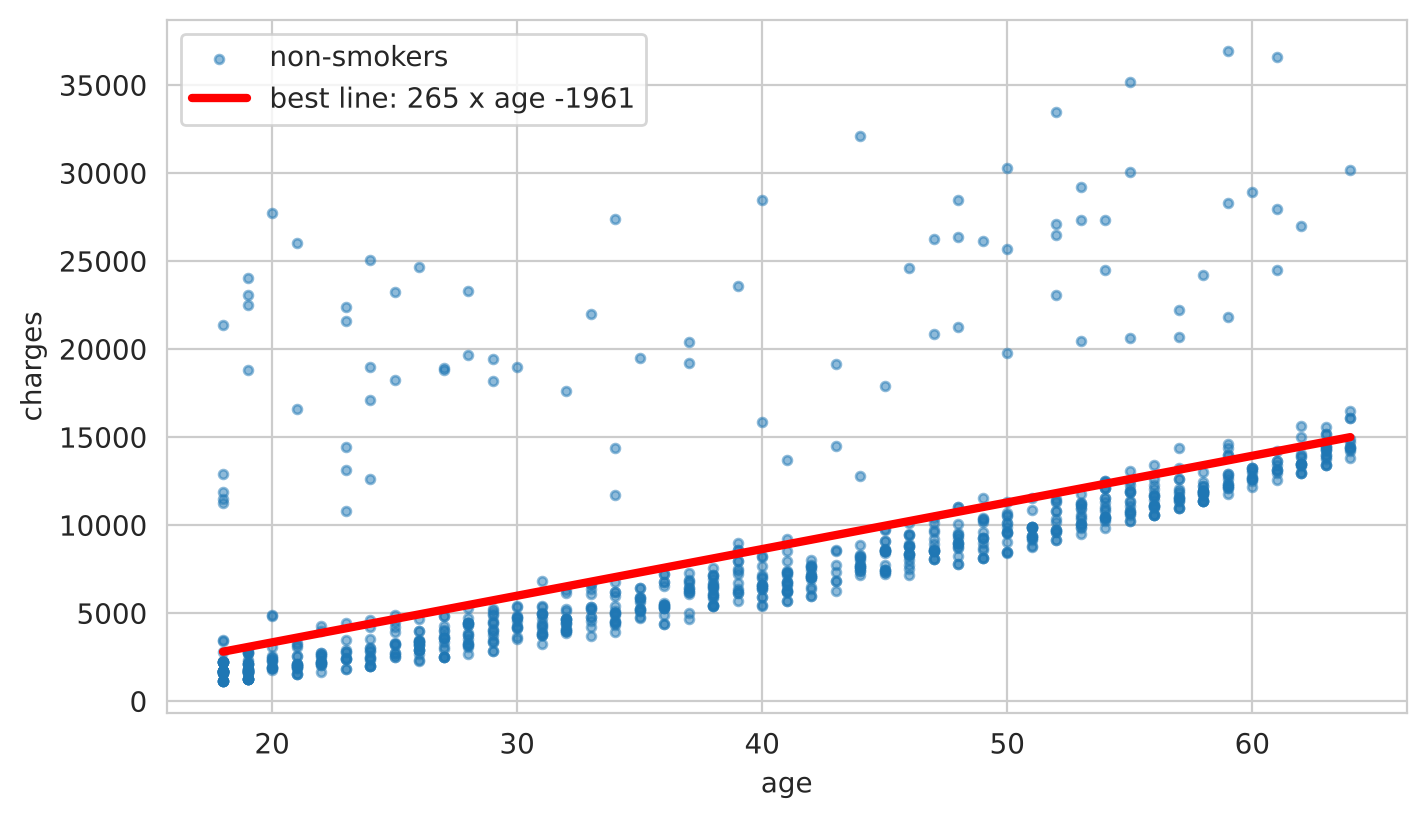

In [18]:
non_smokers = train_df[train_df['smoker'] == 'no']
line = LinearRegression().fit(non_smokers[['age']], non_smokers['charges'])
w, b = line.coef_[0], line.intercept_
print(f'w = {w:.2f} dollars per year of age')
print(f'b = {b:.2f}')

ages = np.array([18, 64])
plt.scatter(non_smokers['age'], non_smokers['charges'], s=10, alpha=.5, label='non-smokers')
plt.plot(ages, w * ages + b, 'r', linewidth=3, label=f'best line: {w:.0f} x age {b:+.0f}')
plt.xlabel('age'); plt.ylabel('charges'); plt.legend(); plt.show()

**Reading it:** each extra year of age adds about **\$265** a year in charges for non-smokers. The line sits a little above most dots because a few expensive customers pull it up: squared error punishes big misses heavily.

### How did it find w and b? Gradient descent, by hand
`LinearRegression` uses a direct formula. Big models instead use **gradient descent**: start with any w and b, measure the error, nudge w and b downhill, repeat. Here it is in a few lines. Same answer:

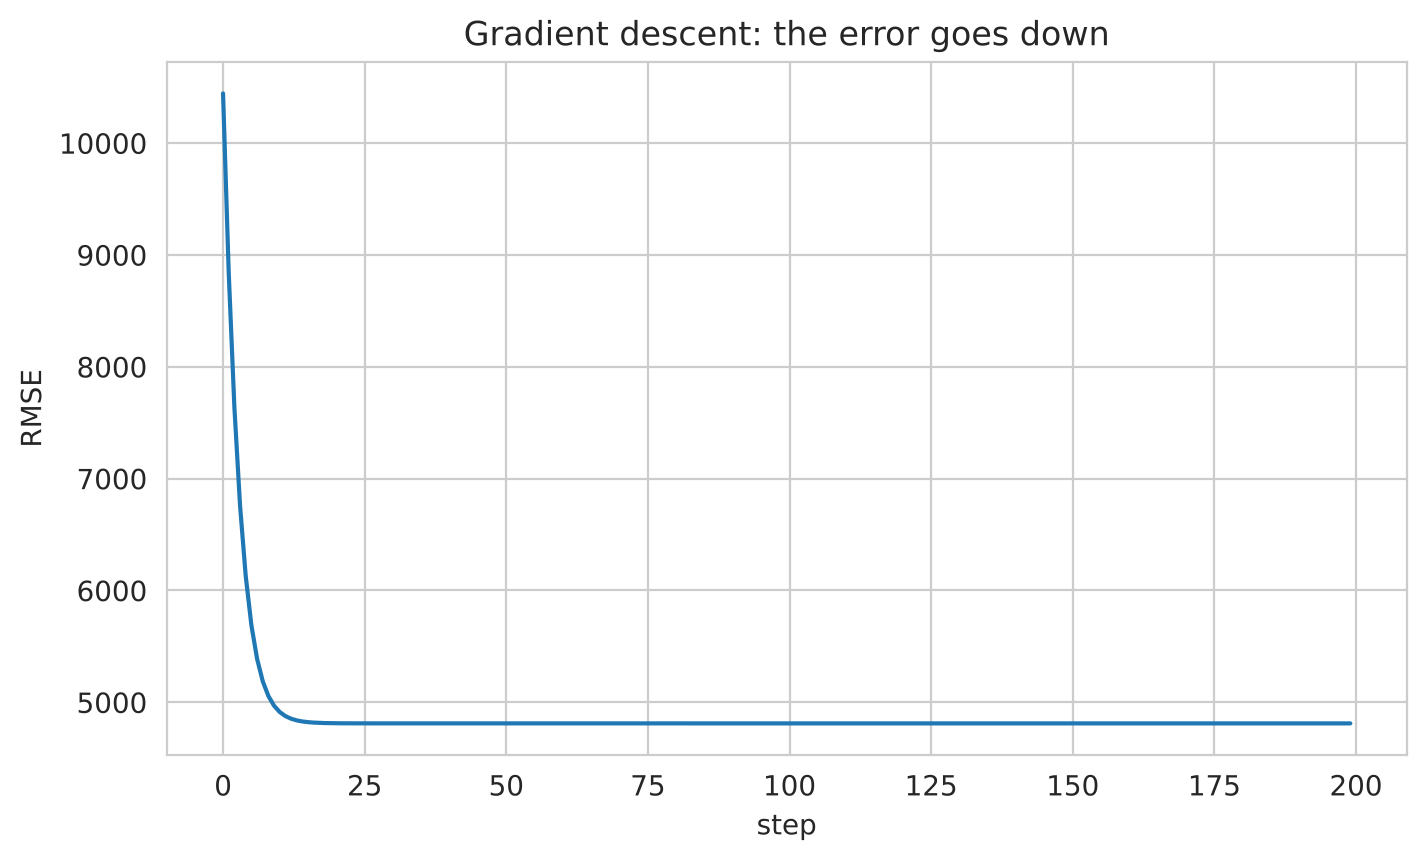

Gradient descent: w = 264.98, b = -1960.57


In [19]:
x = non_smokers['age'].values
y = non_smokers['charges'].values
x_scaled = (x - x.mean()) / x.std()        # scaling makes gradient descent fast and stable
w_s, b_s, learning_rate = 0.0, 0.0, 0.1
errors = []
for step in range(200):
    pred = w_s * x_scaled + b_s
    error = pred - y
    w_s -= learning_rate * 2 * np.mean(error * x_scaled)   # slope of the squared error for w
    b_s -= learning_rate * 2 * np.mean(error)              # slope of the squared error for b
    errors.append(np.sqrt(np.mean(error ** 2)))
plt.plot(errors); plt.xlabel('step'); plt.ylabel('RMSE'); plt.title('Gradient descent: the error goes down'); plt.show()
print(f'Gradient descent: w = {w_s / x.std():.2f}, b = {b_s - w_s * x.mean() / x.std():.2f}')

## Step 15 (continued) · Train on all features, with the pipeline

In [20]:
evaluate('Linear regression (all features)', linear)

,MAE,RMSE,R2
Baseline (predict the mean),"8,789.32","11,688.80",-0.00
Linear regression (all features),"4,221.96","6,123.65",0.72


Big improvement over the baseline: R² ≈ 0.72, MAE ≈ \$4,200. Let's look inside the model:

In [21]:
linear.fit(X_train, y_train)
names = linear.named_steps['preprocess'].get_feature_names_out()
weights = pd.Series(linear.named_steps['model'].coef_, index=names).sort_values()
print('Intercept (base charge):', round(linear.named_steps['model'].intercept_))
weights.round(0)

Intercept (base charge): 8948


cat__region_southeast     -839.00
cat__region_southwest     -659.00
cat__region_northwest     -392.00
cat__sex_male             -102.00
num__children              637.00
num__bmi                 1,928.00
num__age                 3,473.00
cat__smoker_yes         23,078.00
dtype: float64

**Reading the weights** (numbers are scaled, so one unit = one standard deviation):
- being a smoker adds about **\$23,000**
- one standard deviation of age (~14 years) adds ~\$3,500; BMI ~\$1,900
- sex and region matter little

## Step 16 · Evaluate: read the mistakes (residuals)
A **residual** = actual − predicted. If the model captured everything, residuals would look like random noise. **A pattern in the residuals = something the model missed.** We use cross-validated predictions so every customer is predicted by a model that didn't train on them.

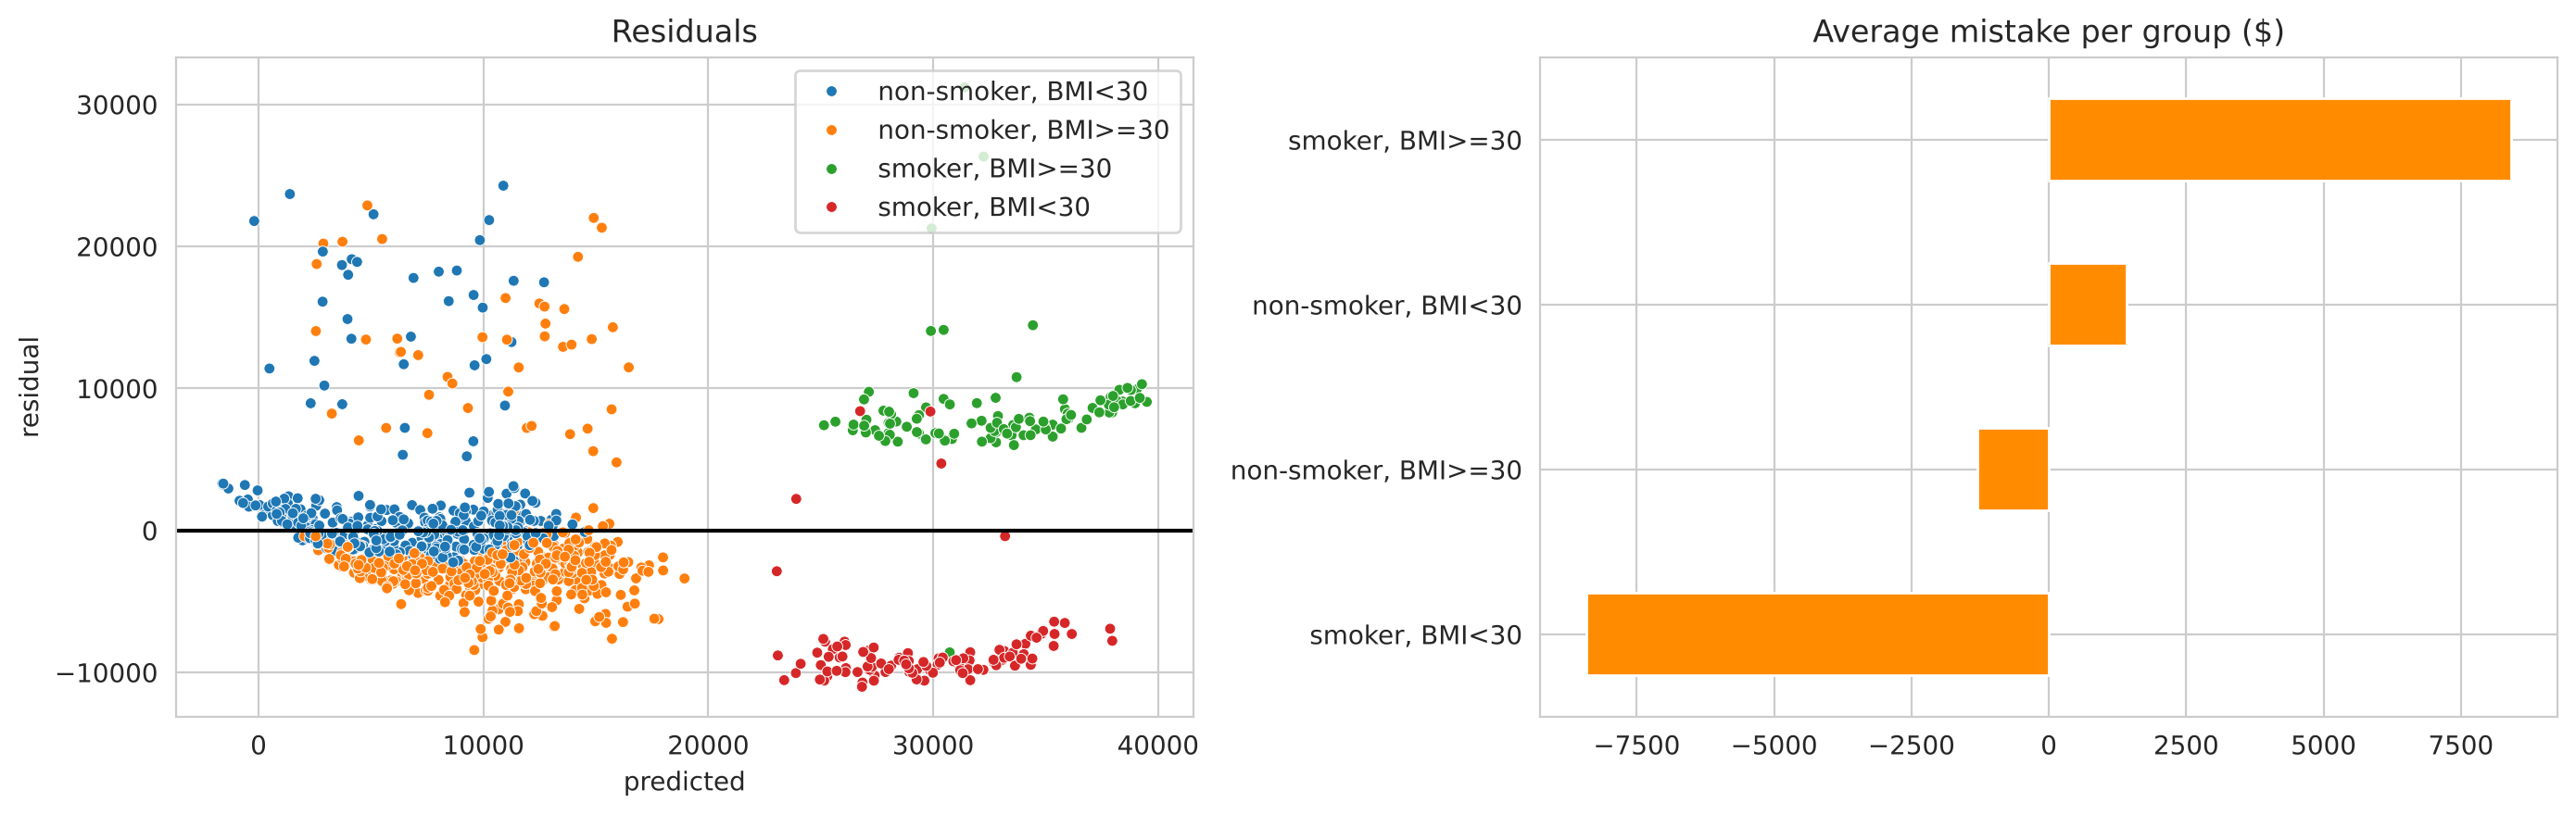

In [22]:
from sklearn.model_selection import cross_val_predict
pred = cross_val_predict(linear, X_train, y_train, cv=folds)
residual = y_train - pred
group = np.where(X_train['smoker'] == 'yes', 'smoker', 'non-smoker') + np.where(X_train['bmi'] >= 30, ', BMI>=30', ', BMI<30')
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.scatterplot(x=pred, y=residual, hue=group, s=18, ax=ax[0]); ax[0].axhline(0, color='black')
ax[0].set_xlabel('predicted'); ax[0].set_ylabel('residual'); ax[0].set_title('Residuals')
pd.Series(residual.values).groupby(group).mean().sort_values().plot.barh(ax=ax[1], color='darkorange')
ax[1].set_title('Average mistake per group ($)'); plt.tight_layout(); plt.show()

**Not random!** Smokers with BMI ≥ 30 are **under**-predicted by about \$8,000; smokers with BMI < 30 are **over**-predicted by about \$8,000. This is the interaction from Finding 3: the model gives every smoker the same bonus, but obese smokers cost much more.

## Step 11 · Feature engineering: teach the model what it missed
New columns from domain knowledge:
- `obese` = 1 if BMI ≥ 30 (a medical threshold)
- `smoker_obese` = smoker × obese, so obese smokers can get their own extra charge
- `age2` = age², so the line can curve upward for older people

We put this inside the pipeline with a `FunctionTransformer`, so new customers get the same columns automatically.

In [23]:
from sklearn.preprocessing import FunctionTransformer

def add_features(data):
    data = data.copy()
    data['smoker_yes'] = (data['smoker'] == 'yes').astype(int)
    data['obese'] = (data['bmi'] >= 30).astype(int)
    data['smoker_obese'] = data['smoker_yes'] * data['obese']
    data['age2'] = data['age'] ** 2
    return data

preprocess_fe = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), ['age', 'age2', 'bmi', 'children']),
    ('bin', 'passthrough', ['smoker_yes', 'obese', 'smoker_obese']),
    ('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                      ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore'))]), ['sex', 'region']),
])
linear_fe = Pipeline([('features', FunctionTransformer(add_features)), ('preprocess', preprocess_fe), ('model', LinearRegression())])
evaluate('Linear regression + engineered features', linear_fe)

,MAE,RMSE,R2
Baseline (predict the mean),"8,789.32","11,688.80",-0.00
Linear regression (all features),"4,221.96","6,123.65",0.72
Linear regression + engineered features,"2,487.81","4,535.72",0.85


**A huge jump:** MAE from ~\$4,200 to ~**\$2,500**, R² from 0.72 to **0.85**. Same algorithm, better **features**. And we found the feature by **reading the mistakes**.

## Step 17 · Compare with regularised versions (Ridge and Lasso)
**Ridge** shrinks all weights a little; **Lasso** can shrink useless weights to exactly zero. Both fight **overfitting**. Will they help here?

In [24]:
from sklearn.linear_model import Ridge, Lasso
evaluate('Ridge (alpha=1)', Pipeline([('features', FunctionTransformer(add_features)), ('preprocess', preprocess_fe), ('model', Ridge(alpha=1))]))
evaluate('Lasso (alpha=10)', Pipeline([('features', FunctionTransformer(add_features)), ('preprocess', preprocess_fe), ('model', Lasso(alpha=10, max_iter=50000))]))

,MAE,RMSE,R2
Baseline (predict the mean),"8,789.32","11,688.80",-0.00
Linear regression (all features),"4,221.96","6,123.65",0.72
Linear regression + engineered features,"2,487.81","4,535.72",0.85
Ridge (alpha=1),"2,496.85","4,535.46",0.85
Lasso (alpha=10),"2,497.30","4,532.51",0.85


**No real change.** Regularisation cures **overfitting**, but our model has only ~11 weights and ~1,000 customers: it isn't overfitting. Medicine for the wrong disease doesn't help. Always diagnose first: too simple (underfitting) or too complex (overfitting)?

## Step 18 · Tune a hyperparameter with GridSearchCV
`alpha` (penalty strength) is a **hyperparameter**: we choose it. `GridSearchCV` tries each value with cross-validation and keeps the best.

In [25]:
from sklearn.model_selection import GridSearchCV
ridge_fe = Pipeline([('features', FunctionTransformer(add_features)), ('preprocess', preprocess_fe), ('model', Ridge())])
search = GridSearchCV(ridge_fe, {'model__alpha': [0.01, 0.1, 1, 10, 100]}, cv=folds, scoring='neg_mean_absolute_error')
search.fit(X_train, y_train)
print('Best alpha:', search.best_params_['model__alpha'], '| CV MAE:', round(-search.best_score_))
pd.DataFrame({'alpha': [str(a) for a in search.cv_results_['param_model__alpha']], 'CV MAE': (-search.cv_results_['mean_test_score']).round(0)})

Best alpha: 0.01 | CV MAE: 2488


,alpha,CV MAE
0,0.01,"2,488.00"
1,0.1,"2,489.00"
2,1.0,"2,497.00"
3,10.0,"2,661.00"
4,100.0,"4,403.00"


Small alphas (0.01–1) all score about the same; stronger penalties (10, 100) make the model worse by shrinking useful weights too much. That confirms: no overfitting to fix.

### The leaderboard so far

In [26]:
pd.DataFrame(results).T.sort_values('MAE')

,MAE,RMSE,R2
Linear regression + engineered features,"2,487.81","4,535.72",0.85
Ridge (alpha=1),"2,496.85","4,535.46",0.85
Lasso (alpha=10),"2,497.30","4,532.51",0.85
Linear regression (all features),"4,221.96","6,123.65",0.72
Baseline (predict the mean),"8,789.32","11,688.80",-0.00


## Step 19 · Final test, once
Winner: **linear regression + engineered features** (best cross-validated MAE, and simple to explain). Now, for the first and only time, we open the test set.

Test MAE : $2,394
Test RMSE: $4,158
Test R2  : 0.906


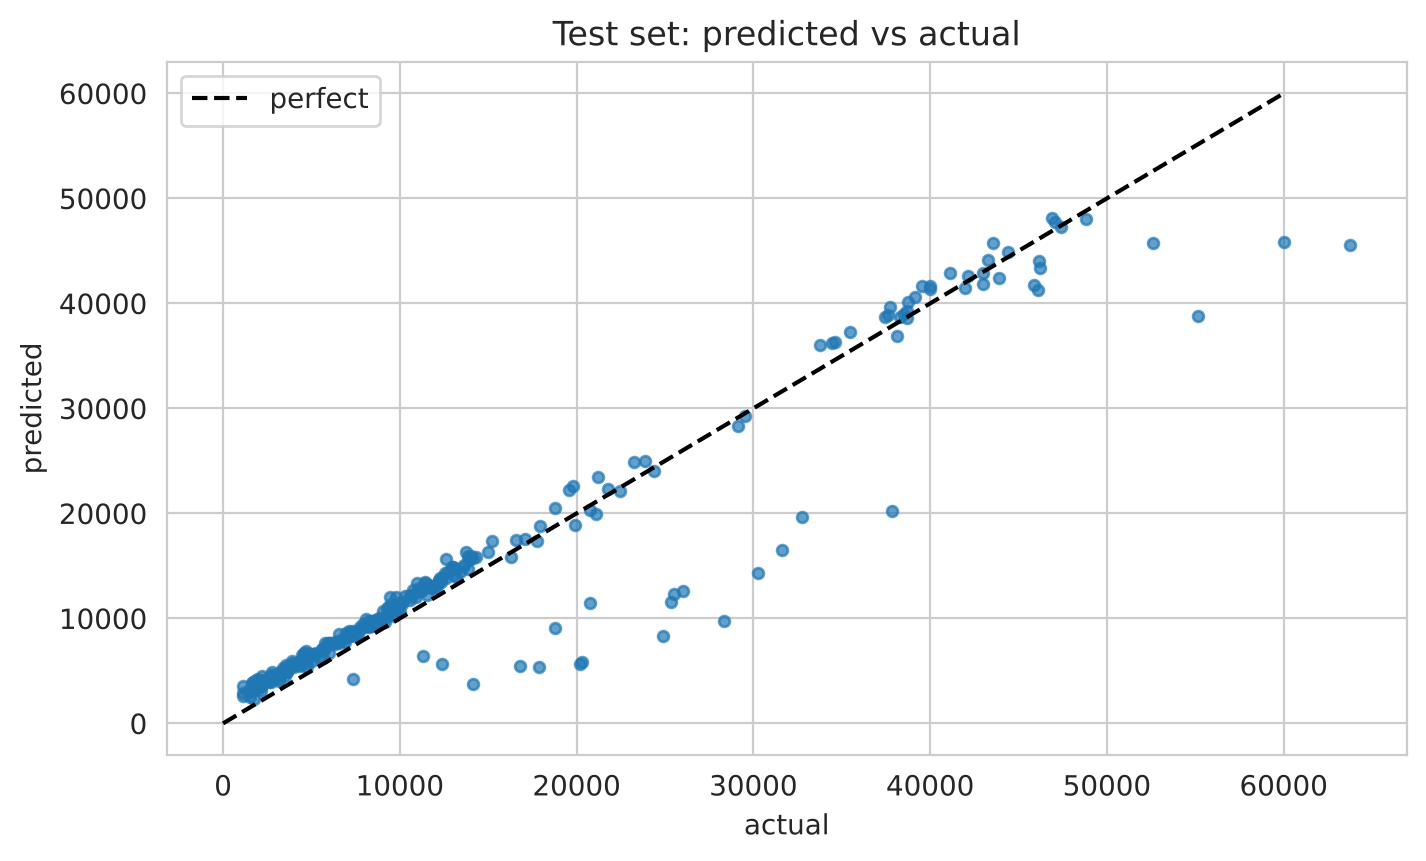

In [27]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
final = linear_fe.fit(X_train, y_train)
test_pred = final.predict(X_test)
print(f'Test MAE : ${mean_absolute_error(y_test, test_pred):,.0f}')
print(f'Test RMSE: ${np.sqrt(mean_squared_error(y_test, test_pred)):,.0f}')
print(f'Test R2  : {r2_score(y_test, test_pred):.3f}')
plt.scatter(y_test, test_pred, s=15, alpha=.7); plt.plot([0, 60000], [0, 60000], 'k--', label='perfect')
plt.xlabel('actual'); plt.ylabel('predicted'); plt.legend(); plt.title('Test set: predicted vs actual'); plt.show()

The test score agrees with cross-validation (it is even slightly better: normal luck with 268 customers), so our estimate was honest.

**Where are the remaining errors?** Some customers cost far more than predicted, mostly non-smokers with expensive medical events. That information (medical history) **is not in our data**. No model can learn what isn't there.

## Step 20 · Save the model and use it for a new customer

In [28]:
import joblib
joblib.dump(final, 'charges_model.joblib')
loaded = joblib.load('charges_model.joblib')

new_customers = pd.DataFrame([
    {'age': 30, 'sex': 'female', 'bmi': 24.0, 'children': 1, 'smoker': 'no',  'region': 'northeast'},
    {'age': 30, 'sex': 'female', 'bmi': 24.0, 'children': 1, 'smoker': 'yes', 'region': 'northeast'},
    {'age': 30, 'sex': 'female', 'bmi': 34.0, 'children': 1, 'smoker': 'yes', 'region': 'northeast'},
])
new_customers['predicted_charges'] = loaded.predict(new_customers).round(0)
new_customers

,age,sex,bmi,children,smoker,region,predicted_charges
0,30,female,24.00,1,no,northeast,"6,030.00"
1,30,female,24.00,1,yes,northeast,"19,229.00"
2,30,female,34.00,1,yes,northeast,"39,038.00"


Three people, identical except smoking and BMI. Smoking adds ~\$13,000; smoking **and** obesity adds ~\$33,000. The model behaves exactly as the data told us.

## Summary
| Step | What we learned |
|---|---|
| 4 | remove true duplicates before splitting |
| 5 | charts revealed the smoker × BMI interaction |
| 13 | baseline MAE ≈ \$9,000 |
| 15 | linear regression = finding the best w and b (by formula or gradient descent) |
| 16 | residuals showed what the model missed |
| 11 | one engineered feature beat every other trick |
| 17–18 | regularisation and tuning don't help a model that isn't overfitting |
| 19 | test score matched cross-validation: honest |
| 20 | one saved pipeline predicts from raw inputs |

## Exercises
1. Remove `sex` and `region` from the features. Does the cross-validated MAE change? What would you tell the business?
2. Add `age × smoker` as another feature. Does it help?
3. Replace `LinearRegression` with `DecisionTreeRegressor(max_depth=4)` in the first pipeline. Does the tree find the interaction without engineered features?